# 07 · Stories Pair v2: an engine that learns from every accept and decline

Notebooks 03-05 built **v1**: everything history can measure (who pairs, with which category, what each item earns
at each branch) plus one **assumption** it cannot measure, how often customers accept a suggestion. Notebook 05
showed that this assumption drives most of the uncertainty.

**v2 removes the assumption over time.** It is a **Thompson-sampling contextual bandit**, a standard reinforcement-learning
method for "which option should I show?" problems:

| Piece | What it is |
|---|---|
| Arm | (first-item category, suggested item, discount): 9 categories x ~22 items x 4 discounts |
| Belief | a Beta distribution over each arm's *take rate*, P(suggested item ends up in the basket) |
| Warm start | every belief starts at v1's estimate, worth 30 suggestions, so it starts from v1's knowledge, not from zero |
| Decision | for each order, draw a take rate from each allowed arm, multiply by that branch's profit, suggest the best draw |
| Learning | each night, add the day's accepts and declines to the beliefs and refresh the till's lookup table |

Uncertain arms sometimes win the draw, so the engine keeps testing them; arms that keep failing stop being drawn.
Acceptance is learned jointly across branches (notebook 01: behaviour does not differ by branch) while profit always
uses each branch's own prices and costs. All guardrails from v1 still apply.

**How we test it.** Stories has no suggestion logs yet, so we simulate. We draw **30 hypothetical "truths"** from the
assumption ranges in `config/assumptions.json`, and in each one the true acceptance of every individual item deviates
randomly from v1's "acceptance follows popularity" rule (lognormal, about ±60%). Every policy then serves the same
year of orders resampled from real April-June orders, and we compare profit with an **oracle** that knows the truth.

**What we find**
- **v2 earns about $27k in its first year vs $21k for v1** (+27%), and beats v1 in 87% of the 30 truths and the
  best-seller rule and the classic combo in 100% of them.
- It pays for a short exploration phase in the first weeks (51% of the oracle's profit in week 1 vs 64% for v1),
  overtakes v1 by week 4, and reaches 87% of the oracle by week 52. v1 never improves on its 64%.
- Its beliefs converge on the truth: for the most-used arm below, v1's prior said 21% take rate, v2 learned 38%,
  the truth was 37%.
- v2 learns how much discounting pays: its discount use rises with the true discount effect (r = 0.72), without being told.
- **Caveat:** these are simulations built on our own model structure. They show the learning loop works and is safe
  to deploy; the real numbers come from the pilot.

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from storiespair import data, models, engine as E, bandit as B, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

lines = data.load_lines()
orders = data.build_orders(lines)
added = data.other_side_first_item(lines, orders)
ue = data.unit_economics(lines)
cfg = E.load_config()
pm = models.PairModels.fit(orders, lines, added)
engine = E.PairEngine(pm, ue, cfg["compatibility"], E.Assumptions.from_config(cfg), E.Guardrails.from_config(cfg))
discounts = np.array(engine.g.discount_grid)

pool = orders[orders.month >= 4]                       # recent orders to resample from
per_day = orders.groupby("first_side").size() / orders.day.nunique()
sides = {}
for side, target in [("drink", "food"), ("food", "drink")]:
    sd = B.side_data(engine, pool[pool.first_side == side], target)
    sides[side] = (sd, B.prior_take(sd, engine.a, discounts), int(round(per_day[side])))
print({s: f"{len(v[0].items)} items x {len(discounts)} discounts x {len(v[0].cats)} categories, {v[2]} orders/day" for s, v in sides.items()})

{'drink': '22 items x 4 discounts x 4 categories, 103 orders/day', 'food': '23 items x 4 discounts x 5 categories, 84 orders/day'}


## 1. Run the simulation (30 truths x 52 weeks x 5 policies)

In [2]:
N_WORLDS, DAYS = 30, 364
POLICY_NAMES = {"oracle": "Oracle (knows the truth)", "thompson": "Stories Pair v2 (learning)",
                "static": "Stories Pair v1 (assumption only)", "most_popular": "Suggest the best-seller",
                "fixed_combo_10": "Classic 10% combo"}
t0 = time.time()
runs, worlds = [], []
for w in range(N_WORLDS):
    rng = np.random.default_rng(1000 + w)
    for side, (sd, prior, n) in sides.items():
        world = B.World.draw(rng, len(sd.cats), len(sd.items), cfg["assumptions"])
        daily, picks, _ = B.simulate(sd, world, prior, discounts, days=DAYS, orders_per_day=n, seed=w)
        daily["world"], daily["side"] = w, side
        runs.append(daily)
        worlds.append({"world": w, "side": side, "true_base_acceptance": world.base_acceptance,
                       "true_discount_lift": world.discount_lift, "true_switch_rate": world.switch_rate})
runs = pd.concat(runs, ignore_index=True)
worlds = pd.DataFrame(worlds)
print(f"Simulated {N_WORLDS} worlds x {DAYS} days in {time.time() - t0:.0f}s")

Simulated 30 worlds x 364 days in 53s


## 2. Learning curve: share of the oracle's profit each policy captures

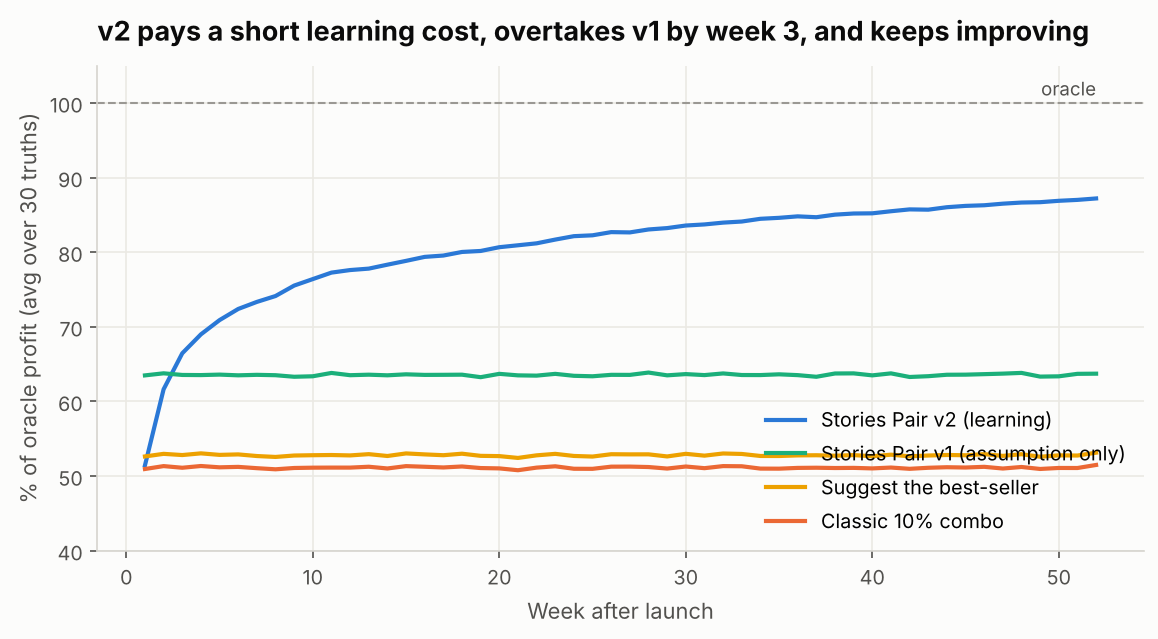

In [3]:
runs["week"] = runs.day // 7
wk = runs.groupby(["world", "week", "policy"]).expected_incremental_gp.sum().unstack()
share = wk.div(wk["oracle"], axis=0).groupby("week").mean()
fig, ax = plt.subplots(figsize=(9, 4.2))
for p, col in [("thompson", viz.BLUE), ("static", viz.AQUA), ("most_popular", viz.YELLOW), ("fixed_combo_10", viz.ORANGE)]:
    ax.plot(share.index + 1, share[p] * 100, color=col, label=POLICY_NAMES[p])
ax.axhline(100, color=viz.GREY, ls="--", lw=1)
ax.text(52, 101, "oracle", ha="right", color=viz.INK_2, fontsize=9)
ax.set_xlabel("Week after launch"); ax.set_ylabel("% of oracle profit (avg over 30 truths)")
ax.set_title("v2 pays a short learning cost, overtakes v1 by week 3, and keeps improving")
ax.legend(loc="lower right")
ax.set_ylim(40, 105)
viz.savefig(fig, "07_learning_curve")
plt.show()

In [4]:
summary = share.loc[[0, 3, 7, 25, 51]].T * 100
summary.columns = ["week 1", "week 4", "week 8", "week 26", "week 52"]
summary.index = [POLICY_NAMES[p] for p in summary.index]
summary.round(1)

,week 1,week 4,week 8,week 26,week 52
Classic 10% combo,50.9,51.3,50.9,51.3,51.5
Suggest the best-seller,52.6,53.0,52.6,52.9,53.1
Oracle (knows the truth),100.0,100.0,100.0,100.0,100.0
Stories Pair v1 (assumption only),63.5,63.5,63.5,63.6,63.7
Stories Pair v2 (learning),51.4,69.0,74.1,82.7,87.2


## 3. A year of profit

In [5]:
offer_rate = cfg["assumptions"]["offer_rate"]["base"]
yr = runs.groupby(["world", "policy"]).expected_incremental_gp.sum().unstack() * offer_rate
table = pd.DataFrame({"mean": yr.mean(), "P10": yr.quantile(0.1), "P90": yr.quantile(0.9)}).loc[list(POLICY_NAMES)]
table["v2 beats it in % of truths"] = [np.nan if p in ("thompson", "oracle") else (yr["thompson"] > yr[p]).mean() * 100 for p in table.index]
table.index = [POLICY_NAMES[p] for p in table.index]
print(f"Incremental gross profit over the first year, staff make the suggestion on {offer_rate:.0%} of orders:")
table.style.format({"mean": "${:,.0f}", "P10": "${:,.0f}", "P90": "${:,.0f}", "v2 beats it in % of truths": "{:.0f}%"}, na_rep="-")

Incremental gross profit over the first year, staff make the suggestion on 80% of orders:


,mean,P10,P90,v2 beats it in % of truths
Oracle (knows the truth),"$33,387","$22,789","$42,706",-
Stories Pair v2 (learning),"$27,379","$17,570","$38,524",-
Stories Pair v1 (assumption only),"$21,478","$15,028","$33,567",87%
Suggest the best-seller,"$17,938","$10,764","$27,495",100%
Classic 10% combo,"$17,425","$10,392","$26,355",100%


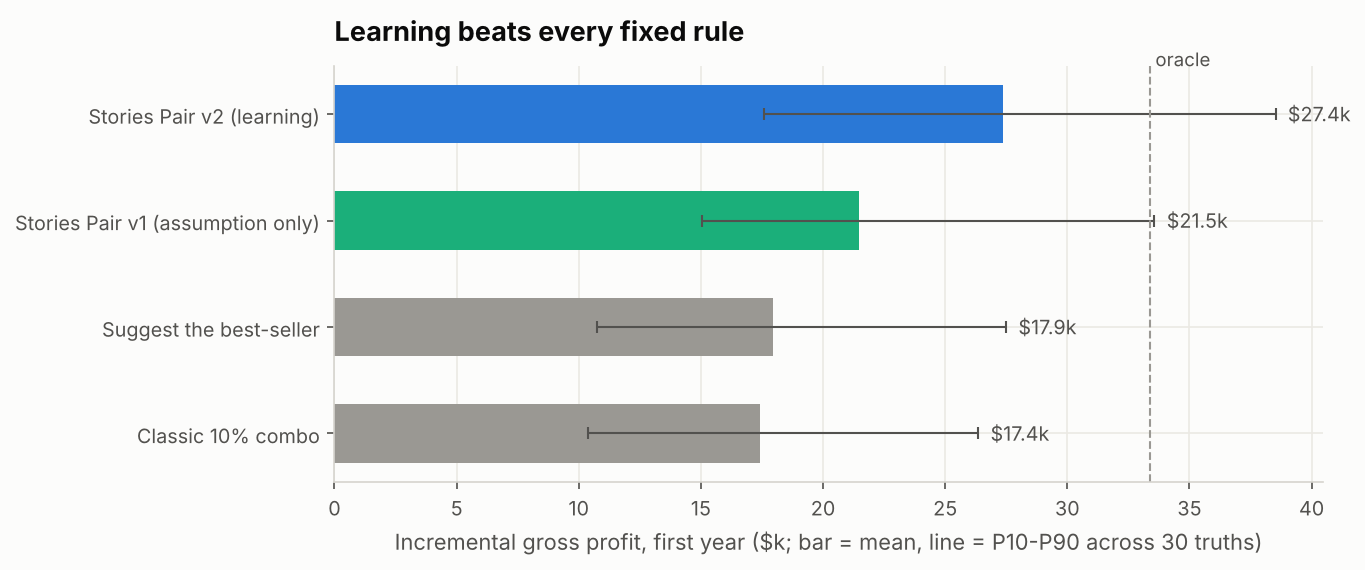

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
order_ = ["fixed_combo_10", "most_popular", "static", "thompson"]
vals = yr[order_].mean() / 1000
lo, hi = yr[order_].quantile(0.1) / 1000, yr[order_].quantile(0.9) / 1000
cols = [viz.GREY, viz.GREY, viz.AQUA, viz.BLUE]
y = np.arange(len(order_))
ax.barh(y, vals, color=cols, height=0.55)
ax.errorbar(vals, y, xerr=[vals - lo, hi - vals], fmt="none", ecolor=viz.INK_2, lw=1, capsize=3)
ax.set_yticks(y, [POLICY_NAMES[p] for p in order_])
for i, v in enumerate(vals):
    ax.text(hi.iloc[i] + 0.5, i, f"${v:,.1f}k", va="center", fontsize=9.5, color=viz.INK_2)
ax.axvline(yr["oracle"].mean() / 1000, color=viz.GREY, ls="--", lw=1)
ax.text(yr["oracle"].mean() / 1000, 3.45, " oracle", color=viz.INK_2, fontsize=9)
ax.set_xlabel("Incremental gross profit, first year ($k; bar = mean, line = P10-P90 across 30 truths)")
ax.set_title("Learning beats every fixed rule")
viz.savefig(fig, "07_year_profit")
plt.show()

The levels here are higher than notebook 05's $17k because the 30 truths span the whole assumption range (acceptance
up to 12%, discount effects up to +50%), not just the base case. Compare policies **within** this table, not across
notebooks.

## 4. Does v2 discover when discounts pay?

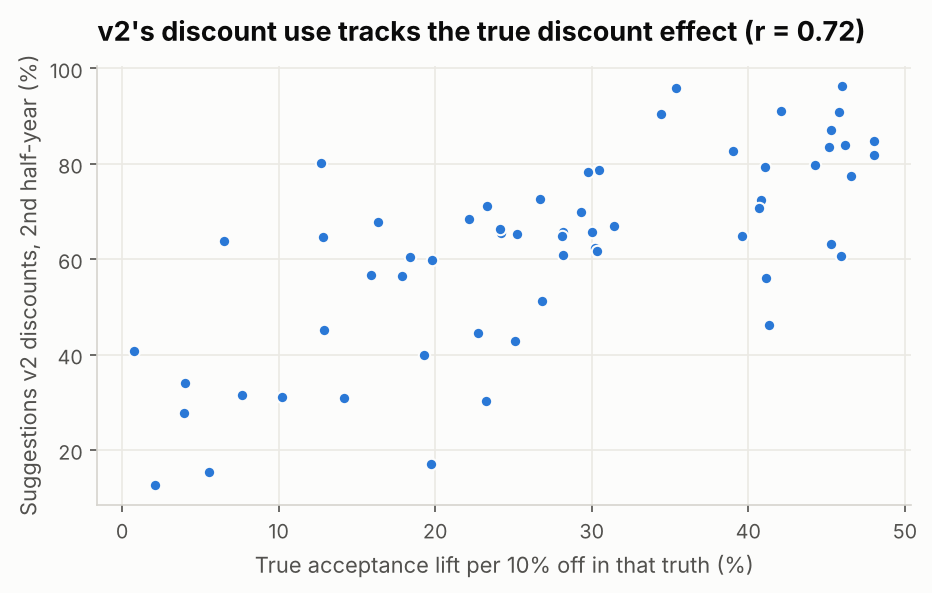

In [7]:
disc_use = runs[runs.policy == "thompson"].groupby(["world", "side"]).discount_share.mean().rename("v2_discount_share").reset_index()
disc_use = disc_use.merge(worlds, on=["world", "side"])
late = runs[(runs.policy == "thompson") & (runs.day >= 182)].groupby(["world", "side"]).discount_share.mean().rename("v2_discount_share_h2").reset_index()
disc_use = disc_use.merge(late, on=["world", "side"])
r = np.corrcoef(disc_use.true_discount_lift, disc_use.v2_discount_share_h2)[0, 1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(disc_use.true_discount_lift * 100, disc_use.v2_discount_share_h2 * 100, color=viz.BLUE, s=30, edgecolor=viz.SURFACE)
ax.set_xlabel("True acceptance lift per 10% off in that truth (%)")
ax.set_ylabel("Suggestions v2 discounts, 2nd half-year (%)")
ax.set_title(f"v2's discount use tracks the true discount effect (r = {r:.2f})")
viz.savefig(fig, "07_discount_discovery")
plt.show()

Nobody tells v2 how customers respond to discounts. The stronger the true effect, the more it discounts. Where the
effect is weak it still discounts a minority of suggestions, because Thompson sampling keeps testing arms whose value
is close; a production version can add a small "discount penalty" if Stories prefers fewer discounts. Either way,
"should we run combo discounts?" becomes a measured answer per category instead of a debate.

## 5. What the engine believes after a year (one truth, Matcha & Tea rung first)

In [8]:
sd, prior, n = sides["drink"]
rng = np.random.default_rng(1000)
world = B.World.draw(rng, len(sd.cats), len(sd.items), cfg["assumptions"])
_, picks, (alpha, beta, truth) = B.simulate(sd, world, prior, discounts, days=DAYS, orders_per_day=n, seed=0)
c = sd.cats.index("Matcha & Tea")
a, b = alpha["thompson"][c], beta["thompson"][c]
post_mean, n_obs = a / (a + b), (a + b) - 30
rows = []
for m in range(len(sd.items)):
    for d in range(len(discounts)):
        if n_obs[m, d] >= 20:
            rows.append({"suggested item": sd.items[m], "discount": f"{discounts[d]:.0%}", "suggestions": int(n_obs[m, d]),
                         "v1 prior": prior[c, m, d], "v2 belief": post_mean[m, d], "truth": truth[c, m, d]})
belief = pd.DataFrame(rows).sort_values("suggestions", ascending=False).head(8)
belief.style.format({"v1 prior": "{:.1%}", "v2 belief": "{:.1%}", "truth": "{:.1%}"})

,suggested item,discount,suggestions,v1 prior,v2 belief,truth
4,Butter Croissant,0%,7151,21.1%,38.2%,37.2%
6,Butter Croissant,10%,1200,22.4%,45.2%,45.5%
5,Butter Croissant,5%,1026,21.7%,40.9%,41.4%
27,Chicken Salad Bowl,5%,97,5.1%,6.7%,5.6%
21,Halloumi Wrap,5%,86,6.0%,8.4%,8.3%
32,Quinoa Bowl,10%,71,5.0%,7.4%,5.5%
31,Quinoa Bowl,5%,69,5.0%,7.6%,5.4%
20,Halloumi Wrap,0%,67,5.9%,6.0%,7.9%


The arms v2 used most have beliefs that moved from v1's prior towards the truth. Arms it stopped using keep wider
beliefs, which is fine: they were not worth the experiments.

## 6. How v2 runs in production

1. **During the day** the till reads a small table: for every (category, item, discount) arm, two counts (accepts,
   declines). Thompson sampling is one random draw per arm; it runs on a phone.
2. **Each night** a job adds the day's accept/decline log to the counts and republishes the table. No retraining, no
   GPU, no customer data.
3. **Monthly** v1's measured parts (pairing rates, category shares, branch prices and costs) are re-fit from the
   transaction export, so the priors stay current.
4. **Guardrails** never change: max discount, minimum margin, affordability, no repeat after a decline.

**Limits.** The simulated truths share our model's structure (acceptance proportional to popularity times an item
deviation). Real customers may differ in ways no simulation covers, such as suggestion fatigue or staff tone. That is
why the pilot in notebook 05 comes first and v2 runs on its log.

In [9]:
viz.savetable(table.reset_index().rename(columns={"index": "policy"}), "07_year_profit_by_policy")
_ = viz.savetable(summary.reset_index().rename(columns={"index": "policy"}), "07_learning_curve_share_of_oracle")